In [1]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib as mpl
import altair as alt
#import pandas as pd
import numpy as np

import mygene
import pyperclip

import glob
import os
import sys
import math

mpl.rcParams.update({
    "pdf.fonttype": 42,           # TrueType = editable text
    "font.family": "Arial", # or Arial, Helvetica
    "text.usetex": False          # Absolutely must be False
})

In [2]:
INPUT_DIR = "/Users/p.coli/Desktop/tximport_quant/0A_KALLISTO QUANT V1-3/V3_ensembl_kallisto_quant/05_DESeq2/"
OUTPUT_DIR = "/Users/p.coli/Desktop/tximport_quant/0A_KALLISTO QUANT V1-3/V3_ensembl_kallisto_quant/06_statistical_analysis/"
CD55_ID = "ENSG00000196352.18"

In [3]:
DESeq_dict = {}
for file in glob.glob(f"{INPUT_DIR}*.csv"):
    plot_name = (os.path.basename(file)).split("_")[0]
    df = pl.read_csv(file, null_values=["NA"])
    df = (df.rename({"": "GENEID"}) #rename column1
          .with_columns(
              [pl.when(pl.col("padj") == 0)  #if pval is so low, it is read as 0, readjust value so can -log10
              .then(1e-300)
              .otherwise(pl.col("padj"))
              .alias("padj"),])
          .with_columns(score=-pl.col("padj").log(base=10),) #-log10 values
          .with_columns(pl.when(pl.col("GENEID") == CD55_ID) #for plotting. sets gene if interest (here CD55) as red, else gray
            .then(pl.lit("red"))
            .otherwise(pl.lit('gray'))
            .alias('color'))
          .with_columns((-pl.col("log2FoldChange")) #artifact of Deseq2 order. Sets everything to be -log2(Control/experiment)
            .alias("-log2FoldChange"))
         )
    DESeq_dict.update({plot_name:df})

In [7]:
for key in DESeq_dict.keys():
    print(key)

CRISPRi
CRISPRtune
dCas9


In [9]:
DESeq_dict["CRISPRi"].filter(pl.col("color") == "red")#.select("-log2FoldChange")#.item()

GENEID,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,score,color,-log2FoldChange
str,f64,f64,f64,f64,f64,f64,f64,str,f64
"""ENSG00000196352.18""",8524.469334,5.573983,0.100006,55.736762,0.0,1.0000e-300,300.0,"""red""",-5.573983


In [11]:
tuple_dict = {}
for key in DESeq_dict.keys():
    dictionary_tuple = (
        DESeq_dict[key].filter(pl.col("color") == "red").select("-log2FoldChange").item(),
        DESeq_dict[key].filter(pl.col("color") == "red").select("score").item()
    )
    tuple_dict.update({key: dictionary_tuple})

In [13]:
for key in DESeq_dict.keys():
    print(key, tuple_dict[key])

CRISPRi (-5.57398310386764, 299.99999999999994)
CRISPRtune (-1.66515805511142, 45.275811119827864)
dCas9 (-1.0188364691337, 14.091906634492084)


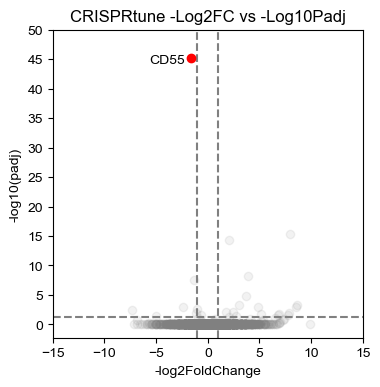

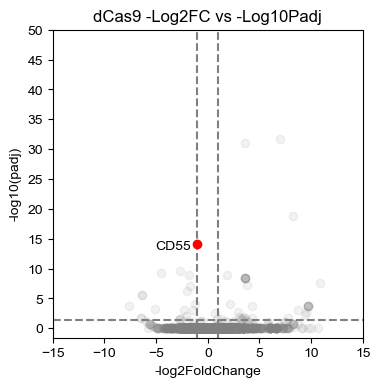

In [15]:
xticks = np.arange(-15, 16, 5)
yticks = np.arange(0, 51, 5)

for key in ["CRISPRtune","dCas9"]:
    fig, ax = plt.subplots(1, 1, figsize=(4, 4))
    for (c,), g in DESeq_dict[key].group_by("color"):
        if c == "red":
            alpha = 1
            zorder = 10
        else:
            alpha = 0.1
            zorder = 5
        ax.scatter(g["-log2FoldChange"], g["score"], color=c, alpha=alpha, zorder=zorder,rasterized=True,)

    ax.set_xticks(xticks)
    ax.set_yticks(yticks)
    
    ax.set_xlabel("-log2FoldChange")
    ax.set_ylabel("-log10(padj)")

    plt.axvline(x=-1, color='gray', linestyle='--', label='Cutoff')
    plt.axvline(x=1, color='gray', linestyle='--', label='Cutoff')
    plt.axhline(y=1.3010299956639813, color='gray', linestyle='--', label='Cutoff')
    ax.set_title(f"{key} -Log2FC vs -Log10Padj", fontsize=12, color="black")
    mpl.rcParams['svg.fonttype'] = 'none'
    
    ax.annotate("CD55", tuple_dict[key],
                textcoords="offset points", 
                xytext=(-30, -4),)
    # fig.savefig(OUTPUT_DIR + "png/" +f"V3_{key}_NT_sgRNA_vs_CD55_sgRNA.png", format="png", dpi = 500)
    # fig.savefig(OUTPUT_DIR + "svg/" +f"V3_{key}_NT_sgRNA_vs_CD55_sgRNA.svg", format="svg", dpi = 300)



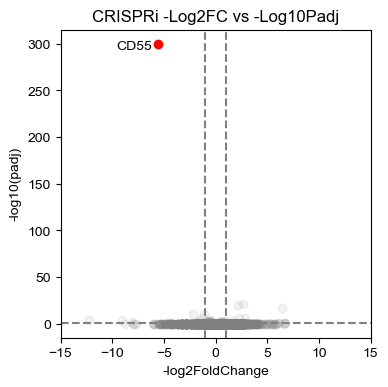

In [351]:
CRISPRifig, ax = plt.subplots(1, 1, figsize=(4, 4))
for (c,), g in DESeq_dict["CRISPRi"].group_by("color"):
    if c == "red":
        alpha = 1
        zorder = 10
    else:
        alpha = 0.1
        zorder = 5
    ax.scatter(g["-log2FoldChange"], g["score"], color=c, alpha=alpha, zorder=zorder,rasterized=True,)

ax.set_xticks(xticks)
#ax.set_yticks(yticks)

ax.set_xlabel("-log2FoldChange")
ax.set_ylabel("-log10(padj)")

plt.axvline(x=-1, color='gray', linestyle='--', label='Cutoff')
plt.axvline(x=1, color='gray', linestyle='--', label='Cutoff')
plt.axhline(y=1.3010299956639813, color='gray', linestyle='--', label='Cutoff')
ax.set_title("CRISPRi -Log2FC vs -Log10Padj", fontsize=12, color="black")
plt.rcParams['font.family'] = 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'

ax.annotate("CD55", tuple_dict["CRISPRi"],
            textcoords="offset points", 
            xytext=(-30, -4),)
CRISPRifig.savefig(OUTPUT_DIR + "png/" +"V3_CRISPRi_NT_sgRNA_vs_CD55_sgRNA.png", format="png", dpi = 500)
CRISPRifig.savefig(OUTPUT_DIR + "svg/" +"V3_CRISPRi_NT_sgRNA_vs_CD55_sgRNA.svg", format="svg", dpi = 300)



In [379]:
[key for key in DESeq_dict.keys()]
upregulated_df = {}
for i in [key for key in DESeq_dict.keys()]:
    upreg = DESeq_dict[key].filter(
        (pl.col("-log2FoldChange") > 1) & (pl.col("score") > 1.3010299956639813)
        
    )
    

['CRISPRi', 'CRISPRtune', 'dCas9']

In [297]:
upreg=DESeq_dict["CRISPRi"].filter(
    (pl.col("-log2FoldChange") > 1) & (pl.col("score") > 1.3010299956639813)
)#["GENEID"].to_list()

ensembl_ids=upreg.with_columns(pl.col("GENEID")
    .str.split(".")
    .list.get(0)
    .alias("ensembl_id_clean")
)["ensembl_id_clean"].to_list()

In [299]:
mg = mygene.MyGeneInfo()
results=mg.querymany(ensembl_ids, scopes='ensembl.gene', fields='symbol', species='human')
id_to_symbol = {r['query']: r.get('symbol', None) for r in results}

Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed


In [301]:
id_to_symbol

{'ENSG00000235754': 'APOM',
 'ENSG00000253797': 'UTP14C',
 'ENSG00000278220': 'CLN8',
 'ENSG00000282230': 'ADAM9',
 'ENSG00000286235': None,
 'ENSG00000291729': 'RNF139'}

In [303]:
CRISPRi_gene_name=[]
for key in id_to_symbol.keys():
    CRISPRi_gene_name.append(id_to_symbol[key])
CRISPRi_gene_name

['APOM', 'UTP14C', 'CLN8', 'ADAM9', None, 'RNF139']

In [294]:
dcas9_upreg_df = pl.DataFrame(dCas9_gene_name).rename({'column_0':'dcas9_upreg'})
CRISPRtune_upreg_df = pl.DataFrame(CRISPRtune_gene_name).rename({'column_0':'CRISPRtune_upreg'})

shared_genes = dcas9_upreg_df["dcas9_upreg"].is_in(CRISPRtune_upreg_df["CRISPRtune_upreg"])
dcas9_upreg_df.filter(shared_genes).write_clipboard()


In [305]:
as_text = "\n".join([g if g is not None else "NA" for g in CRISPRi_gene_name])
pyperclip.copy(as_text)


In [375]:
#find downreg genes
CRISPRtune_downreg = DESeq_dict["CRISPRtune"].filter(
    (pl.col("-log2FoldChange") < 1) & (pl.col("score") > 1.3010299956639813)).select(['GENEID','score','-log2FoldChange','color'])

CRISPRtune_downreg.write_clipboard()